# Exploração inicial do Brasileirão Série A

Objetivo: validar a base e produzir um primeiro panorama descritivo de cobertura, gols, resultados e público.

In [35]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [36]:
candidatos = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "projects" / "brasileirao",
]
PROJECT_ROOT = next(
    (p.resolve() for p in candidatos if (p / "data" / "raw").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto brasileirao.")

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "brasileirao_serie_a.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["data"], low_memory=False)
print(f"Arquivo: {DATA_PATH}")
print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

Arquivo: C:\Users\Airton Sammi\airton_sammi_labs\nexo-dados-lab\projects\brasileirao\data\raw\brasileirao_serie_a.csv
Dimensões: 8,453 linhas x 35 colunas


,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,tecnico_visitante,colocacao_mandante,colocacao_visitante,valor_equipe_titular_mandante,valor_equipe_titular_visitante,idade_media_titular_mandante,idade_media_titular_visitante,gols_mandante,gols_visitante,gols_1_tempo_mandante,gols_1_tempo_visitante,escanteios_mandante,escanteios_visitante,faltas_mandante,faltas_visitante,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_mandante,defesas_visitante,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante
0,2005,2005-10-08,31,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,Fluminense,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2005,2005-04-23,1,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,Goiás EC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2005,2005-08-21,21,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,Vasco da Gama,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2005,2005-08-28,23,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,São Paulo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2005,2005-06-26,9,Estádio Olímpico Nilton Santos,NaN,NaN,NaN,Botafogo,Figueirense FC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Qualidade e cobertura

In [37]:
resumo_qualidade = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_pct": (df.isna().mean() * 100).round(1),
    "valores_unicos": df.nunique(dropna=True),
}).sort_values("nulos_pct", ascending=False)
resumo_qualidade

,tipo,nulos,nulos_pct,valores_unicos
chutes_fora_visitante,float64,6366,75.3,15
defesas_visitante,float64,6366,75.3,14
defesas_mandante,float64,6366,75.3,13
faltas_mandante,float64,6366,75.3,32
faltas_visitante,float64,6366,75.3,31
chutes_bola_parada_visitante,float64,6366,75.3,31
chutes_fora_mandante,float64,6366,75.3,18
impedimentos_visitante,float64,6366,75.3,9
impedimentos_mandante,float64,6366,75.3,10
chutes_visitante,float64,6366,75.3,31


In [38]:
print("Linhas duplicadas:", df.duplicated().sum())
print("Período:", df["data"].min(), "a", df["data"].max())

jogos_por_temporada = (
    df.groupby("ano_campeonato", as_index=False)
    .size()
    .rename(columns={"size": "jogos"})
)
jogos_por_temporada.tail(21)

Linhas duplicadas: 0
Período: 2003-03-29 00:00:00 a 2024-10-26 00:00:00


,ano_campeonato,jogos
1,2004,456
2,2005,418
3,2006,380
4,2007,380
5,2008,380
6,2009,380
7,2010,380
8,2011,380
9,2012,380
10,2013,380


## 2. Métricas descritivas

In [39]:
partidas = df.dropna(subset=["gols_mandante", "gols_visitante"]).copy()
partidas["total_gols"] = partidas["gols_mandante"] + partidas["gols_visitante"]
partidas["resultado"] = "Empate" # Inicialmente, todas as partidas são classificadas como empate.
partidas.loc[partidas["gols_mandante"] > partidas["gols_visitante"], "resultado"] = "Mandante"
partidas.loc[partidas["gols_mandante"] < partidas["gols_visitante"], "resultado"] = "Visitante"

display(partidas[["gols_mandante", "gols_visitante", "total_gols", "publico"]].describe().round(2))

display((partidas["resultado"].value_counts(normalize=True).mul(100).round(2)).rename("percentual"))
# Conta quantas vezes aparece cada categoria;
# normalize=True retorna proporções em vez de quantidades.
# mul(100) Multiplica as proporções por 100 para gerar percentuais.


,gols_mandante,gols_visitante,total_gols,publico
count,8452.00,8452.00,8452.00,6742.00
mean,1.53,1.02,2.55,16189.95
std,1.22,1.02,1.63,14074.41
min,0.00,0.00,0.00,0.00
25%,1.00,0.00,1.00,5898.25
50%,1.00,1.00,2.00,12685.50
75%,2.00,2.00,4.00,22963.25
max,7.00,7.00,11.00,82044.00


resultado
Mandante     49.48
Empate       26.60
Visitante    23.92
Name: percentual, dtype: float64

## 3. Gráficos iniciais

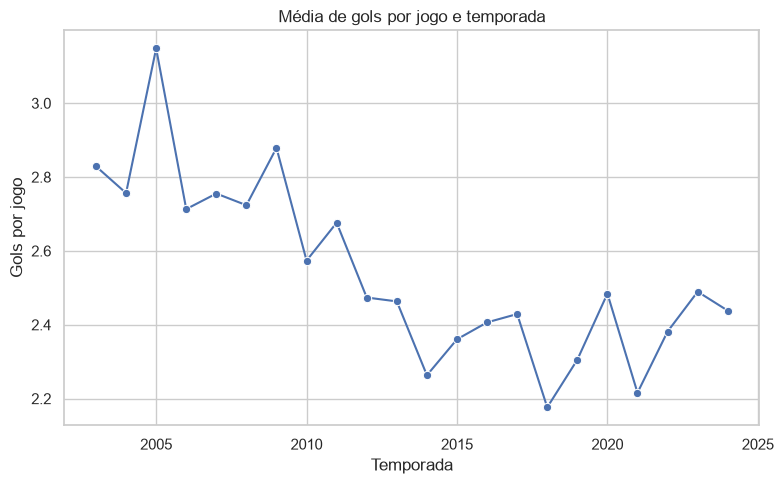

In [40]:
gols_por_temporada = (
    partidas.groupby("ano_campeonato", as_index=False)
    .agg(media_gols=("total_gols", "mean"), jogos=("total_gols", "size"))
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=gols_por_temporada, x="ano_campeonato", y="media_gols", marker="o", ax=ax)
ax.set(title="Média de gols por jogo e temporada", xlabel="Temporada", ylabel="Gols por jogo")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "media_gols_por_temporada.png", dpi=150, bbox_inches="tight")
plt.show()

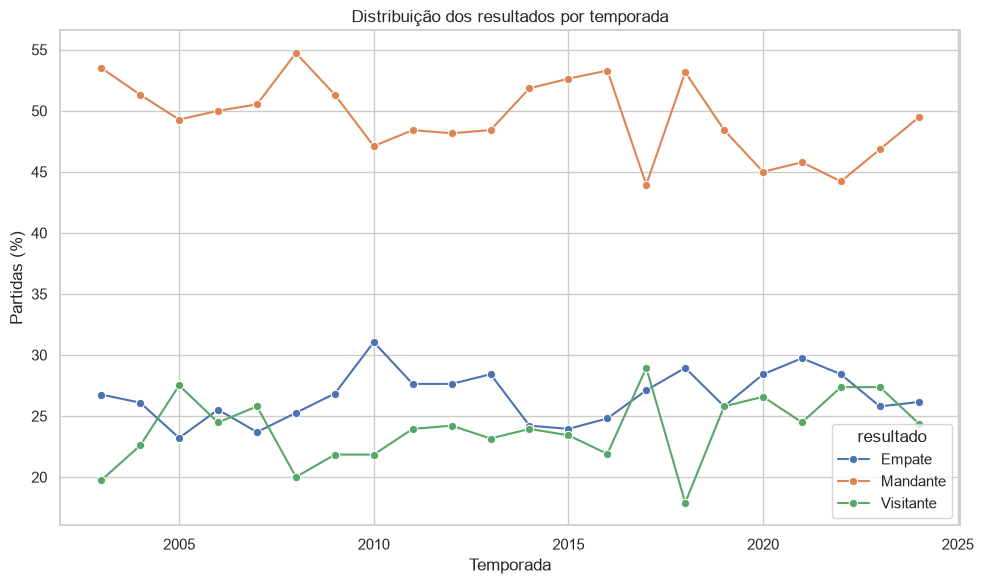

In [41]:
resultado_por_temporada = (# Agrupa as partidas por temporada e tipo de resultado.
    partidas.groupby(["ano_campeonato", "resultado"]).size() # Conta quantas partidas existem em cada combinação.
    .groupby(level=0).transform(lambda s: 100 * s / s.sum()) # Agrupa novamente apenas pelo primeiro nível, que corresponde ao ano do campeonato.
        # .transform(lambda s: 100 * s / s.sum()) Calcula o percentual que cada resultado representa dentro da respectiva temporada.
    .rename("percentual").reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=resultado_por_temporada,
    x="ano_campeonato", y="percentual", hue="resultado", marker="o", ax=ax,
)
ax.set(title="Distribuição dos resultados por temporada", xlabel="Temporada", ylabel="Partidas (%)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "resultados_por_temporada.png", dpi=150, bbox_inches="tight")
plt.show()

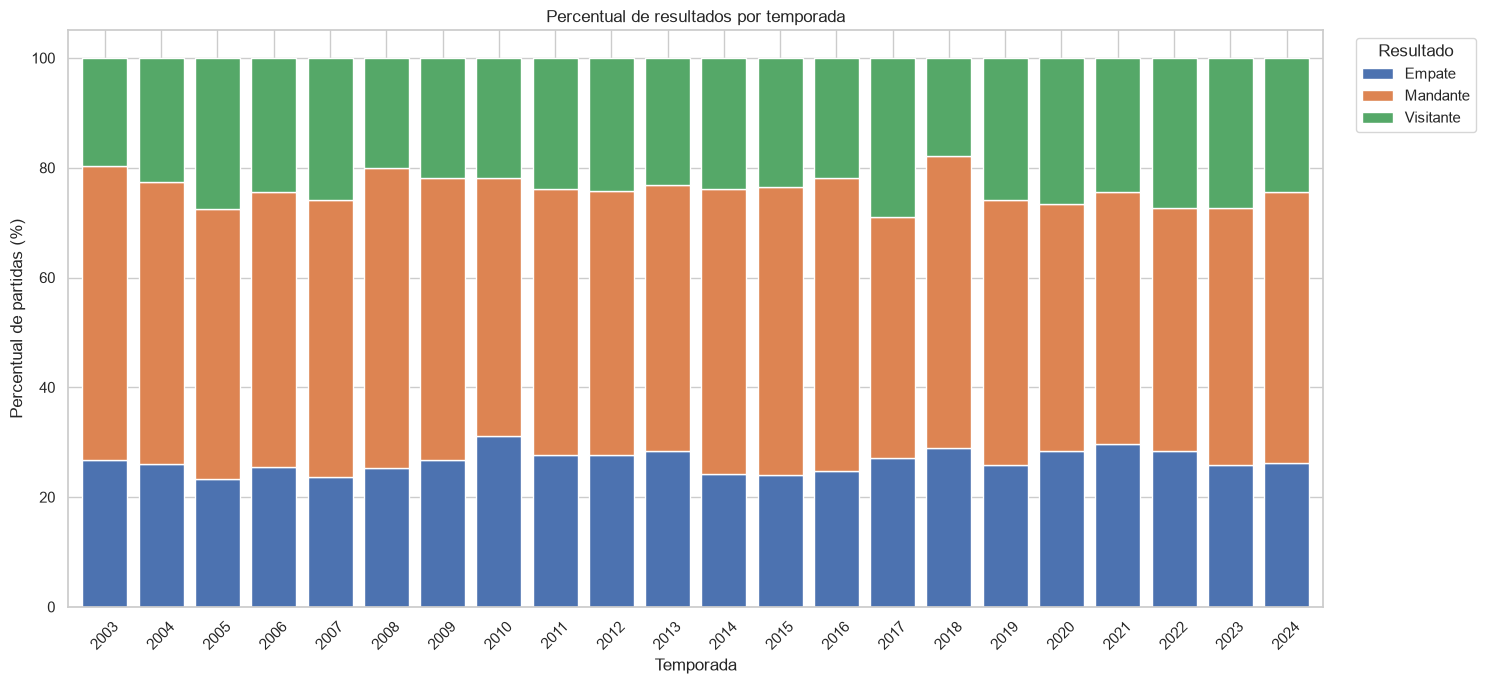

In [42]:


percentual_resultados.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7),
    width=0.8,
)

plt.title("Percentual de resultados por temporada")
plt.xlabel("Temporada")
plt.ylabel("Percentual de partidas (%)")
plt.legend(title="Resultado", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Registro da análise

A análise histórica indica que os mandantes vencem uma parcela maior das partidas do que visitantes, enquanto os empates ocupam uma posição intermediária. Essa diferença é relativamente persistente entre as temporadas, sugerindo a existência de vantagem associada ao mando de campo.
Entretanto, a intensidade dessa vantagem varia ao longo do tempo. As temporadas de 2008 e 2017 apresentam desvios em relação ao comportamento mais comum da série e merecem investigação específica. Antes de interpretar esses anos como mudanças reais, é necessário verificar a quantidade de partidas, a integridade dos dados e a composição dos clubes em cada temporada, para que seja possível inferir se há um desvio dessas temporadas referentes a demais.
Os resultados ainda são descritivos e não demonstram que jogar em casa, isoladamente, cause o aumento das vitórias. Parte da diferença pode ser explicada pela força dos clubes, posição na tabela, valor dos elencos, estádio, público, desempenho ofensivo e defensivo ou outros fatores não observados.
A próxima etapa será identificar quais características estão associadas à vitória do mandante e verificar se a vantagem permanece depois de controlar essas diferenças.

## 5. Taxa de vit?rias como mandante por time

Cada observa??o do boxplot representa a taxa de vit?rias em casa de um time em uma temporada. Os times s?o ordenados da esquerda para a direita pela taxa geral de vit?rias como mandante, calculada sobre todas as partidas com placar v?lido.

In [ ]:
partidas_mandante = partidas.dropna(
    subset=["gols_mandante", "gols_visitante"]
).copy()
partidas_mandante["vitoria_mandante"] = (
    partidas_mandante["gols_mandante"] > partidas_mandante["gols_visitante"]
).astype(int)

taxa_por_time_temporada = (
    partidas_mandante.groupby(["time_mandante", "ano_campeonato"], as_index=False)
    .agg(
        jogos_validos=("vitoria_mandante", "size"),
        vitorias=("vitoria_mandante", "sum"),
    )
)
taxa_por_time_temporada["taxa_vitoria_pct"] = (
    taxa_por_time_temporada["vitorias"]
    / taxa_por_time_temporada["jogos_validos"]
    * 100
)

ordem_times = (
    taxa_por_time_temporada.groupby("time_mandante")
    .agg(jogos=("jogos_validos", "sum"), vitorias=("vitorias", "sum"))
    .assign(taxa_geral=lambda resumo: 100 * resumo["vitorias"] / resumo["jogos"])
    .sort_values("taxa_geral", ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(20, 7))
sns.boxplot(
    data=taxa_por_time_temporada,
    x="time_mandante",
    y="taxa_vitoria_pct",
    order=ordem_times,
    ax=ax,
)
ax.set(
    title="Taxa de vit?rias como mandante por time e temporada",
    xlabel="Time mandante (ordenado pela taxa geral de vit?rias)",
    ylabel="Vit?rias em casa por temporada (%)",
    ylim=(0, 100),
)
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "taxa_vitoria_mandante_por_time.png", dpi=150, bbox_inches="tight")
plt.show()